# Chapter 4. Training Models — Practice Notebook

## Linear Regression

Generating linear synthetic data using: $y = 4 + 3x + \text{Gaussian noise}$.

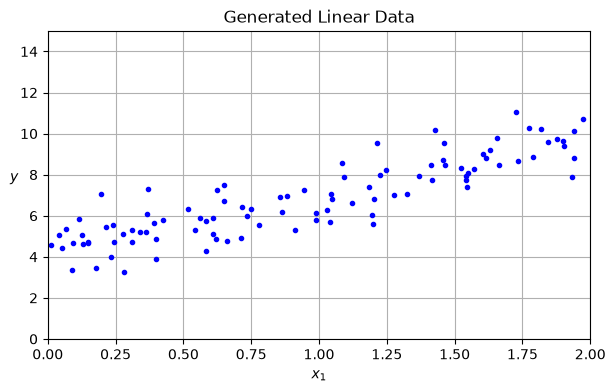

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

plt.figure(figsize=(7, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.title("Generated Linear Data")
plt.show()

**Output meaning:** A scattered cloud of 100 points trending upwards around the true line $y = 4 + 3x$. The noise keeps them from being perfectly aligned.

### The Normal Equation

Computing $\hat{\mathbf{\theta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$ directly in one step. We add $x_0 = 1$ to `X` for the bias term $\theta_0$.

In [2]:
X_b = np.c_[np.ones((100, 1)), X]  # add x0 = 1
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

print("Estimated theta_0 (intercept):", theta_best[0][0])
print("Estimated theta_1 (slope):    ", theta_best[1][0])

Estimated theta_0 (intercept): 4.21509615754675
Estimated theta_1 (slope):     2.7701133864384806


**Output meaning:** The model found $\theta_0 \approx 4.215$ and $\theta_1 \approx 2.770$ (very close to true $4$ and $3$). The slight difference is due to the random noise.

### Making Predictions with The Normal Equation

Predicting $y$ on new points ($x_1 = 0$ and $x_1 = 2$) and plotting the fitted line.

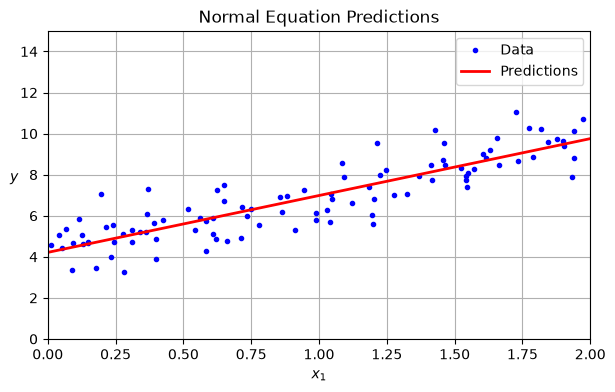

In [3]:
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
y_predict = X_new_b @ theta_best

plt.figure(figsize=(7, 4))
plt.plot(X, y, "b.", label="Data")
plt.plot(X_new, y_predict, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.legend()
plt.title("Normal Equation Predictions")
plt.show()

**Output meaning:** The red regression line cuts straight through the middle of the points, minimizing the Mean Squared Error (MSE).

### Computational Complexity & SVD Pseudoinverse

Scikit-Learn's `LinearRegression` uses SVD pseudoinverse ($\hat{\mathbf{\theta}} = \mathbf{X}^+ \mathbf{y}$) instead of inverting $(\mathbf{X}^T \mathbf{X})$ directly.

In [4]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)

print("Intercept (theta_0):", lin_reg.intercept_)
print("Slope (theta_1):    ", lin_reg.coef_)
print("Predictions on [0, 2]:\n", lin_reg.predict(X_new))

Intercept (theta_0): [4.21509616]
Slope (theta_1):     [[2.77011339]]
Predictions on [0, 2]:
 [[4.21509616]
 [9.75532293]]


In [5]:
# Direct SVD pseudoinverse via NumPy: theta = pinv(X_b) @ y
theta_svd = np.linalg.pinv(X_b) @ y
print("Theta via np.linalg.pinv:\n", theta_svd)

Theta via np.linalg.pinv:
 [[4.21509616]
 [2.77011339]]


**Output meaning:** Gives identical results to the Normal Equation, but SVD is faster ($\mathcal{O}(n^2)$ vs $\mathcal{O}(n^3)$) and never crashes if features are collinear (redundant).

---
## Gradient Descent
### Batch Gradient Descent

Starting from random $\theta$, we compute the gradient over all 100 instances at each step:
$$\mathbf{\theta}^{(\text{next step})} = \mathbf{\theta} - \eta \nabla_{\mathbf{\theta}}\text{MSE}(\mathbf{\theta})$$

Final theta found by Batch GD:
 [[4.21509616]
 [2.77011339]]


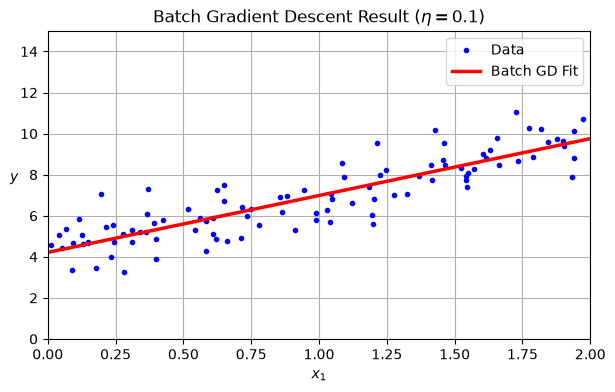

In [6]:
eta = 0.1  # learning rate
n_iterations = 1000
m = len(X_b)

# Random initialization
np.random.seed(42)
theta = np.random.randn(2, 1)

for iteration in range(n_iterations):
    gradients = 2/m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients

print("Final theta found by Batch GD:\n", theta)

# Predictions on [0, 2]
y_predict_bgd = X_new_b @ theta

# Plot fitted line
plt.figure(figsize=(7, 4))
plt.plot(X, y, "b.", label="Data")
plt.plot(X_new, y_predict_bgd, "r-", linewidth=2.5, label="Batch GD Fit")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.legend()
plt.title(r"Batch Gradient Descent Result ($\eta = 0.1$)")
plt.show()

**Output meaning:** Finds the exact same parameters ($\theta_0 \approx 4.215, \theta_1 \approx 2.770$) as the Normal Equation, but via 1,000 small downhill steps instead of inverting matrices.

### Visualizing the Effect of Learning Rate ($\eta$)

Here we plot the first 10 steps taken by Gradient Descent under 3 different learning rates:
- **Red dashed line**: Where the model started (random guess).
- **Blue solid lines**: The first 10 steps taken.

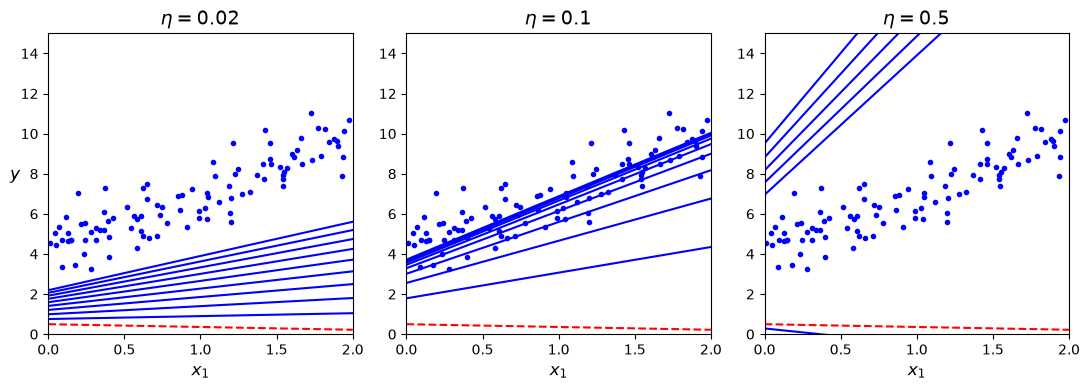

In [7]:
def plot_gradient_descent(theta, eta):
    m = len(X_b)
    plt.plot(X, y, "b.")
    n_iterations = 1000
    for iteration in range(n_iterations):
        if iteration < 10:
            y_predict = X_new_b @ theta
            style = "b-" if iteration > 0 else "r--"
            plt.plot(X_new, y_predict, style)
        gradients = 2/m * X_b.T @ (X_b @ theta - y)
        theta = theta - eta * gradients
    plt.xlabel("$x_1$", fontsize=12)
    plt.axis([0, 2, 0, 15])
    plt.title(fr"$\eta = {eta}$", fontsize=14)

np.random.seed(42)
theta_init = np.random.randn(2, 1)

plt.figure(figsize=(11, 4))
plt.subplot(131)
plot_gradient_descent(theta_init.copy(), eta=0.02)
plt.ylabel("$y$", rotation=0, fontsize=12)

plt.subplot(132)
plot_gradient_descent(theta_init.copy(), eta=0.1)

plt.subplot(133)
plot_gradient_descent(theta_init.copy(), eta=0.5)

plt.tight_layout()
plt.show()

**What the 3 plots show:**
- $\eta = 0.02$ (**Too small**): Barely moves; it will take thousands of iterations to reach the line.
- $\eta = 0.1$ (**Optimal**): In just 10 steps, the lines converge smoothly right onto the center of the points.
- $\eta = 0.5$ (**Too large**): Jumps wildly across the minimum and bounces out of the frame (diverging).

---
### Stochastic Gradient Descent (SGD)

Instead of using all 100 points, SGD picks **one random point** at each step.
A **learning schedule** gradually lowers the learning rate $\eta$ so it stops bouncing and settles near the minimum.

SGD Learned Theta:
 [[4.21076011]
 [2.74856079]]


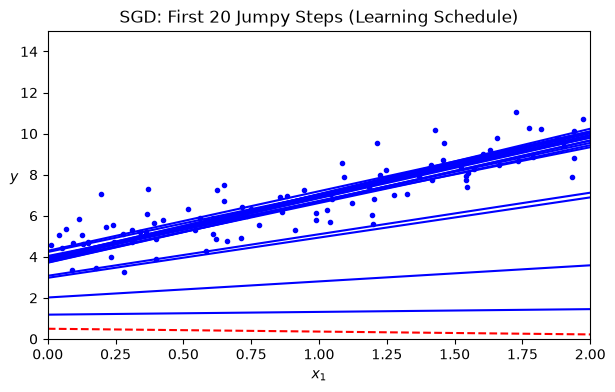

In [8]:
n_epochs = 50
t0, t1 = 5, 50  # learning schedule hyperparameters
m = len(X_b)

def learning_schedule(t):
    return t0 / (t + t1)

np.random.seed(42)
theta = np.random.randn(2, 1)  # random start

plt.figure(figsize=(7, 4))
plt.plot(X, y, "b.")

for epoch in range(n_epochs):
    for i in range(m):
        # Plot the first 20 steps to see the jumpy path
        if epoch == 0 and i < 20:
            y_predict = X_new_b @ theta
            style = "b-" if i > 0 else "r--"
            plt.plot(X_new, y_predict, style)
            
        random_index = np.random.randint(m)
        xi = X_b[random_index:random_index+1]
        yi = y[random_index:random_index+1]
        gradients = 2 * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(epoch * m + i)
        theta = theta - eta * gradients

print("SGD Learned Theta:\n", theta)
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.title("SGD: First 20 Jumpy Steps (Learning Schedule)")
plt.show()

**Output meaning:** Notice how the steps bounce around irregularly. Thanks to the learning schedule, it still settles near the minimum ($\theta_0 \approx 4.19, \theta_1 \approx 2.73$).

### Scikit-Learn's `SGDRegressor` (Production Way)

In real projects, you don't write the loop by hand. Scikit-Learn provides `SGDRegressor`:

In [9]:
from sklearn.linear_model import SGDRegressor

# max_iter=1000 epochs, lr eta0=0.1, no regularization penalty
sgd_reg = SGDRegressor(max_iter=1000, tol=1e-3, penalty=None, eta0=0.1, random_state=42)
sgd_reg.fit(X, y.ravel())

print("SGDRegressor Intercept (theta_0):", sgd_reg.intercept_[0])
print("SGDRegressor Slope     (theta_1):", sgd_reg.coef_[0])

SGDRegressor Intercept (theta_0): 4.243652860329604
SGDRegressor Slope     (theta_1): 2.8250878043833314


**Output meaning:** In just 3 lines, `SGDRegressor` reaches $\theta_0 \approx 4.24$ and $\theta_1 \approx 2.82$. It runs extremely fast and handles massive datasets that do not fit in RAM.